# Bab 11 — Deteksi *Novelty* dan *Outlier*

**Buku:** *scikit-learn Cookbook, Third Edition* — John Sukup (Packt, 2025), Bab 11
**Sumber kode:** [PacktPublishing/Scikit-Learn-Cookbook-Third-Edition](https://github.com/PacktPublishing/Scikit-Learn-Cookbook-Third-Edition) (`Chapter_11`)
**Direproduksi dan dijelaskan oleh:** Hadi Nugroho — NIM 101032330235 — S1 Teknik Komputer, Telkom University

**Resep yang dibahas**

| # | Resep | Alat utama |
|---|--------|-----------|
| 11.1 | Pengantar Deteksi *Outlier* dan *Novelty* | `make_blobs`, `LocalOutlierFactor` |
| 11.2 | Memahami *Isolation Forest* | `IsolationForest`, `contamination` |
| 11.3 | *One-Class SVM* untuk Deteksi *Novelty* | `OneClassSVM`, `nu`, `gamma` |
| 11.4 | *Local Outlier Factor* (LOF) | `LocalOutlierFactor`, kepadatan lokal |
| 11.5 | Mengevaluasi Model Deteksi *Outlier* | `confusion_matrix`, `classification_report`, `roc_auc_score` |
| 11.6 | Menangani *Outlier* yang Terdeteksi | penghapusan, penggantian median, *winsorization* |
| 11.7 | Memilih Teknik Deteksi yang Tepat | tabel perbandingan Isolation Forest / LOF / One-Class SVM |
| 11.8 | Latihan Praktis Deteksi *Novelty* dan *Outlier* | Isolation Forest, LOF, One-Class SVM pada data simulasi |

> Nomor resep ditambahkan di sini untuk memudahkan navigasi; buku aslinya tidak menomori resep. Resep 11.8 memakai solusi resmi dari notebook *Exercise Solutions* di repositori. Walaupun judul latihan menyebut "transaksi kartu kredit", "intrusi jaringan", dan "sensor manufaktur", semua data latihan adalah simulasi `make_blobs`/`np.random`.

## Gambaran Umum Bab

***Outlier*** adalah titik yang sangat berbeda dari sebagian besar data: transaksi penipuan, sensor yang rusak, kesalahan input. Buku membedakan dua tugas:

* ***Outlier detection*** (*unsupervised*): data latih **sudah tercampur** outlier, dan model harus menandai titik yang aneh di dalam data itu sendiri.
* ***Novelty detection*** (*semi-supervised*): model dilatih **hanya pada data normal**, lalu dipakai untuk menilai apakah titik **baru** termasuk normal atau merupakan sesuatu yang belum pernah terlihat.

Tiga algoritme utama dipakai: ***Isolation Forest*** (outlier mudah "diisolasi" dengan sedikit potongan acak), ***Local Outlier Factor*** (outlier berada di daerah yang jauh lebih jarang daripada tetangganya, ide yang sama dengan DBSCAN di Bab 10), dan ***One-Class SVM*** (mempelajari batas daerah normal dengan kernel, kelanjutan Bab 7). Karena outlier jarang, evaluasinya mirip klasifikasi tidak seimbang (Bab 6): *precision*, *recall*, F1, dan ROC-AUC lebih berguna daripada akurasi. Bab ditutup dengan strategi menangani outlier yang ditemukan dan panduan memilih metode.

Konvensi scikit-learn yang dipakai di seluruh bab: `predict`/`fit_predict` mengembalikan **+1 untuk inlier dan −1 untuk outlier**, dan `decision_function` bernilai **negatif untuk outlier** (makin kecil makin aneh).

## Persiapan

In [1]:
# Pustaka inti yang dipakai di sepanjang bab ini
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import seaborn as sns
from collections import Counter

# Satu seed global agar setiap eksekusi notebook menghasilkan angka yang sama.
# (Sel-sel buku tetap memakai nilai random_state masing-masing.)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Catat lingkungan persis yang menghasilkan output di bawah
print(f"Python       : {sys.version.split()[0]}")
print(f"numpy        : {np.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"matplotlib   : {matplotlib.__version__}")

Python       : 3.13.17
numpy        : 2.1.3
pandas       : 2.2.3
scikit-learn : 1.5.2
matplotlib   : 3.9.4


## Resep 11.1 — Pengantar Deteksi *Outlier* dan *Novelty*

**Tujuan.** Membuat 300 titik normal dalam satu kelompok ditambah 20 outlier acak, lalu menandai outlier dengan *Local Outlier Factor*.

### Teori

**Intuisi.** Cara paling sederhana memahami deteksi outlier: tentukan apa yang "normal" dari data mayoritas, lalu ukur seberapa jauh setiap titik menyimpang. Data contoh dibuat sehingga jawabannya diketahui: satu kelompok normal yang rapat ditambah titik-titik yang tersebar acak di kotak besar.

**Matematika.** Titik normal $\mathbf{x}\sim N(\boldsymbol\mu,0{,}6^2I)$ dengan $\boldsymbol\mu$ diambil acak dari kotak $[-10,10]^2$ oleh `make_blobs`; outlier $\mathbf{x}\sim\text{Uniform}([-6,6]^2)$. Model deteksi menghasilkan skor $s(\mathbf{x})$ dan ambang $t$; titik ditandai outlier jika $s(\mathbf{x})<t$. Parameter **`contamination`** menetapkan $t$ sebagai kuantil sehingga proporsi titik yang ditandai sama dengan nilai itu (di sini 5 %, yaitu 16 dari 320 titik).

**Cara scikit-learn mengimplementasikannya.** `LocalOutlierFactor(n_neighbors=20, contamination='auto' | float, novelty=False)`; dengan `novelty=False` hanya `fit_predict` yang tersedia (hasil +1/−1), dan skor ada di `negative_outlier_factor_`. Detail algoritmenya dibahas di Resep 11.4.

**Asumsi, kelebihan, keterbatasan.**

* `contamination` adalah **asumsi** tentang proporsi outlier. Di sini proporsi sebenarnya 20/320 = 6,25 %, sedangkan model diminta menandai 5 %, sehingga paling banyak 16 dari 20 outlier bisa tertangkap.
* Outlier uniform bisa saja jatuh di dalam kelompok normal; titik seperti itu secara statistik tidak bisa dibedakan dari data normal.

### Kode

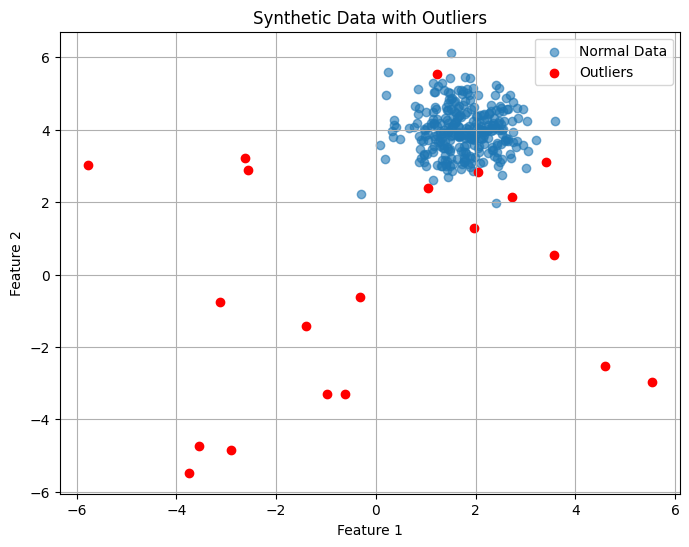

In [2]:
# Muat pustaka
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

# Bangkitkan dataset sintetis dengan outlier yang disengaja
X, _ = make_blobs(n_samples=300, centers=1, cluster_std=0.60, random_state=2024)
np.random.seed(2024)
outliers = np.random.uniform(low=-6, high=6, size=(20, 2))
X_with_outliers = np.vstack([X, outliers])

# Visualisasikan data dengan outlier
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], label="Normal Data", alpha=0.6)
plt.scatter(outliers[:, 0], outliers[:, 1], color='red', label="Outliers")
plt.title("Synthetic Data with Outliers")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

In [3]:
# Lokasi kelompok normal dan jarak outlier dari pusatnya (tambahan)
center = X.mean(axis=0)
d_out = np.linalg.norm(outliers - center, axis=1)
d_in = np.linalg.norm(X - center, axis=1)
print("pusat kelompok normal:", center.round(2), "| deviasi standar per fitur:", X.std(axis=0).round(2))
print(f"jarak titik normal ke pusat: maks {d_in.max():.2f}; jarak outlier ke pusat: min {d_out.min():.2f}, median {np.median(d_out):.2f}")
print("outlier yang jaraknya < jarak maks titik normal:", int((d_out < d_in.max()).sum()))
y_true_11 = np.r_[np.zeros(300, int), np.ones(20, int)]   # 1 = outlier yang disengaja

pusat kelompok normal: [1.76 3.98] | deviasi standar per fitur: [0.61 0.64]
jarak titik normal ke pusat: maks 2.70; jarak outlier ke pusat: min 1.19, median 5.65
outlier yang jaraknya < jarak maks titik normal: 5


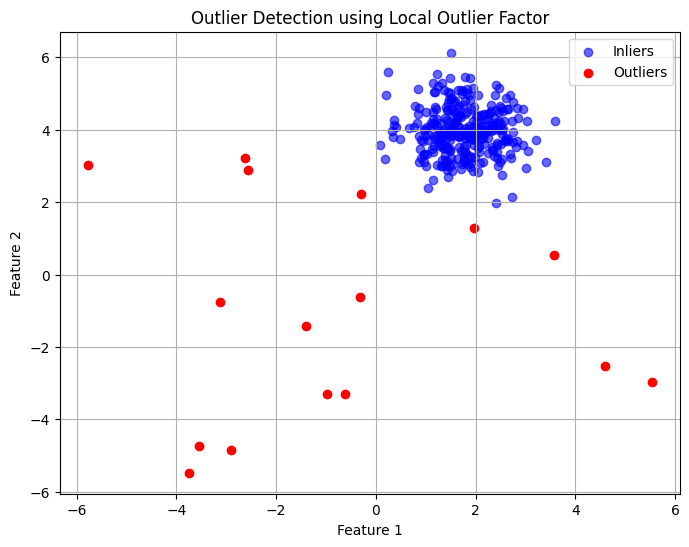

In [4]:
# Muat model
from sklearn.neighbors import LocalOutlierFactor

# Fit model dan prediksi outlier
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
y_pred = lof.fit_predict(X_with_outliers)

# Gambar hasil prediksi
plt.figure(figsize=(8, 6))
plt.scatter(X_with_outliers[y_pred == 1, 0], X_with_outliers[y_pred == 1, 1],
            color='blue', label='Inliers', alpha=0.6)
plt.scatter(X_with_outliers[y_pred == -1, 0], X_with_outliers[y_pred == -1, 1],
            color='red', label='Outliers')
plt.title("Outlier Detection using Local Outlier Factor")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

In [5]:
# Bandingkan tanda LOF dengan outlier yang disengaja (tambahan)
from sklearn.metrics import confusion_matrix
pred_out = (y_pred == -1).astype(int)
tn, fp, fn, tp = confusion_matrix(y_true_11, pred_out).ravel()
print(f"ditandai outlier = {pred_out.sum()} | outlier asli tertangkap = {tp}/20 | normal salah tandai = {fp} | outlier lolos = {fn}")

ditandai outlier = 16 | outlier asli tertangkap = 15/20 | normal salah tandai = 1 | outlier lolos = 5


**Interpretasi output.**

* Kelompok normal berpusat di sekitar (1,76; 3,98) dengan deviasi standar ±0,6, sedangkan 20 outlier tersebar di kotak [−6, 6]². Median jarak outlier ke pusat 5,65, tetapi **5 outlier** jatuh lebih dekat ke pusat daripada titik normal terjauh (2,70). Titik seperti itu praktis tidak bisa dibedakan dari data normal.
* Dengan `contamination=0.05`, LOF menandai tepat **16** titik (5 % dari 320). Dari jumlah itu, **15** adalah outlier asli dan hanya **1** titik normal salah tandai; 5 outlier lolos. Karena model diminta menandai 16 titik padahal outlier sebenarnya 20, minimal 4 outlier pasti lolos. Plot memperlihatkan outlier yang tertangkap adalah titik yang jelas terpencil, sedangkan yang lolos berada dekat atau di dalam kelompok.

### Poin Penting
* *Outlier detection* bekerja pada data tercampur; *novelty detection* dilatih hanya pada data normal.
* `contamination` menetapkan berapa banyak titik yang ditandai (16 dari 320); LOF menangkap 15 dari 20 outlier dengan 1 salah tandai.
* Outlier acak yang jatuh di dalam kelompok normal tidak dapat dideteksi oleh metode apa pun.

## Resep 11.2 — Memahami *Isolation Forest*

**Tujuan.** Mendeteksi outlier pada data yang sama dengan *Isolation Forest*: hutan pohon biner acak yang mengukur seberapa cepat setiap titik terisolasi.

### Teori

**Intuisi.** Alih-alih memodelkan seperti apa data normal, *Isolation Forest* memanfaatkan fakta bahwa outlier itu **sedikit dan berbeda**. Jika data dipotong-potong secara acak (pilih fitur acak, pilih nilai potong acak di antara min dan max), titik yang terpencil akan terpisah sendiri setelah beberapa potongan saja, sedangkan titik di tengah kelompok padat butuh banyak potongan. Panjang jalur dari akar ke daun, dirata-ratakan atas banyak pohon, menjadi skor keanehan.

**Matematika.** Untuk sampel berukuran $\psi$, panjang jalur rata-rata pencarian gagal di pohon biner acak adalah $c(\psi)=2H(\psi-1)-\dfrac{2(\psi-1)}{\psi}$ dengan $H(i)\approx\ln i+0{,}5772$. Skor anomali titik $\mathbf{x}$:
$$s(\mathbf{x},\psi)=2^{-\frac{E[h(\mathbf{x})]}{c(\psi)}},$$
dengan $E[h(\mathbf{x})]$ rata-rata panjang jalur di semua pohon. $s\to1$ berarti sangat mudah diisolasi (outlier), $s\ll0{,}5$ berarti normal. scikit-learn melaporkan `score_samples` $=-s$, dan `decision_function` = `score_samples` − `offset_`, dengan `offset_` dipilih sehingga proporsi `contamination` bernilai negatif.

**Cara scikit-learn mengimplementasikannya.** `IsolationForest(n_estimators=100, max_samples='auto', contamination='auto', max_features=1.0, random_state=None)`.

* Setiap pohon dilatih pada subsampel `max_samples` = min(256, $n$) titik dan tumbuh sampai titik terisolasi atau kedalaman $\lceil\log_2\psi\rceil$.
* `predict` (+1/−1) bisa dipakai untuk titik baru, sehingga cocok untuk outlier **dan** *novelty detection*.

**Asumsi, kelebihan, keterbatasan.**

* Cepat ($O(n\log\psi)$), tidak butuh jarak atau kepadatan, skala baik ke dimensi tinggi.
* Potongan sejajar sumbu: kurang sensitif terhadap outlier yang hanya aneh dalam kombinasi fitur (bukan per fitur). Kurang cocok jika kepadatan antar-*cluster* sangat berbeda.

### Kode

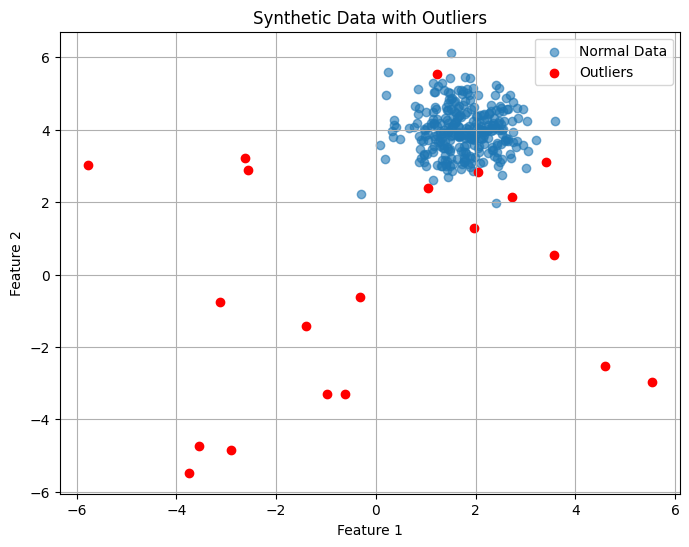

In [6]:
# Muat pustaka
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.datasets import make_blobs

# Bangkitkan data sintetis dengan outlier
X, _ = make_blobs(n_samples=300, centers=1, cluster_std=0.6, random_state=2024)
np.random.seed(2024)
outliers = np.random.uniform(low=-6, high=6, size=(20, 2))
X_combined = np.vstack([X, outliers])

# Visualisasikan data
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], label="Normal Data", alpha=0.6)
plt.scatter(outliers[:, 0], outliers[:, 1], color='red', label="Outliers")
plt.title("Synthetic Data with Outliers")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

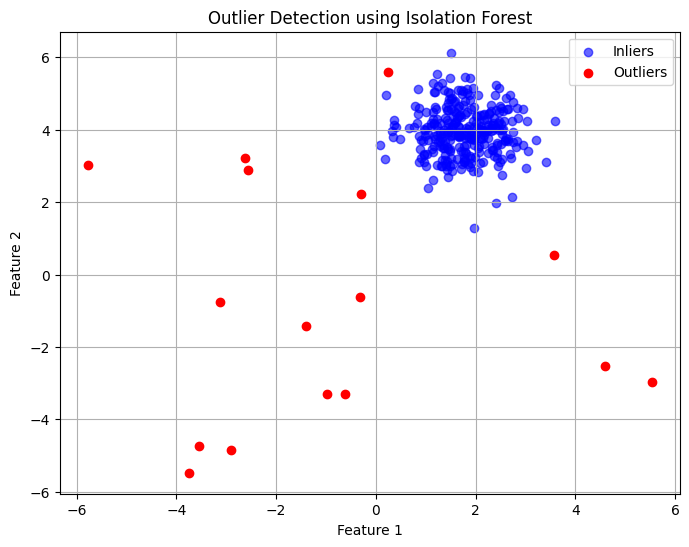

In [7]:
# Muat dan atur model
model = IsolationForest(n_estimators=100, contamination=0.05, random_state=2024)

# Fit model dan buat prediksi
model.fit(X_combined)
y_pred = model.predict(X_combined)

# Gambar hasilnya
plt.figure(figsize=(8, 6))
plt.scatter(X_combined[y_pred == 1, 0], X_combined[y_pred == 1, 1],
            color='blue', label='Inliers', alpha=0.6)
plt.scatter(X_combined[y_pred == -1, 0], X_combined[y_pred == -1, 1],
            color='red', label='Outliers')
plt.title("Outlier Detection using Isolation Forest")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

In [8]:
# Hasil Isolation Forest vs LOF, ROC-AUC skor kontinu, dan skor rata-rata (tambahan)
from sklearn.metrics import roc_auc_score
assert np.array_equal(X_combined, X_with_outliers)       # data identik dengan Resep 11.1
pred_if = (y_pred == -1).astype(int)
tn, fp, fn, tp = confusion_matrix(y_true_11, pred_if).ravel()
print(f"Isolation Forest: tertangkap {tp}/20, normal salah tandai {fp}")
print(f"ROC-AUC (skor kontinu): Isolation Forest = {roc_auc_score(y_true_11, -model.decision_function(X_combined)):.4f}, "
      f"LOF = {roc_auc_score(y_true_11, -lof.negative_outlier_factor_):.4f}")
s = -model.score_samples(X_combined)                    # skor anomali asli paper, 0..1
print(f"skor anomali rata-rata: titik normal {s[:300].mean():.3f}, outlier {s[300:].mean():.3f}; offset_ = {model.offset_:.3f}")

Isolation Forest: tertangkap 14/20, normal salah tandai 2
ROC-AUC (skor kontinu): Isolation Forest = 0.9878, LOF = 0.9882
skor anomali rata-rata: titik normal 0.399, outlier 0.651; offset_ = -0.591


**Interpretasi output.** Data identik dengan Resep 11.1 (dicek dengan `assert`). *Isolation Forest* dengan `contamination=0.05` menandai 16 titik: **14 dari 20** outlier tertangkap dan **2** titik normal salah tandai, sedikit di bawah LOF (15/1). Namun dengan ROC-AUC, yang menilai urutan skor tanpa ambang, keduanya hampir sama: **0,988** (IF) vs **0,988** (LOF). Perbedaan hasil biner hanya terjadi pada satu-dua titik di dekat ambang. Skor anomali asli (skala 0–1 dari paper) rata-rata **0,399** untuk titik normal dan **0,651** untuk outlier, sesuai teori: outlier mendekati 1, titik normal di bawah 0,5.

### Poin Penting
* *Isolation Forest* mengukur seberapa cepat titik terisolasi oleh potongan acak; outlier punya jalur pendek.
* Pada data ini: 14/20 tertangkap, 2 salah tandai, ROC-AUC 0,988 (setara LOF).
* Skor anomali rata-rata 0,40 (normal) vs 0,65 (outlier); `contamination` hanya menggeser ambang.

## Resep 11.3 — *One-Class SVM* untuk Deteksi *Novelty*

**Tujuan.** Melatih *One-Class SVM* hanya pada 300 titik normal, lalu menilai 120 titik uji (100 'normal' + 20 *novelty*).

### Teori

**Intuisi.** *One-Class SVM* mempelajari **batas** daerah tempat data normal berada. Dengan kernel RBF, batas itu bisa berbentuk sembarang (mengikuti bentuk kelompok). Titik baru di luar batas dianggap *novelty*. Karena model hanya melihat data normal saat dilatih, ini adalah *novelty detection*, bukan *outlier detection*.

**Matematika.** Formulasi Schölkopf dkk. memisahkan data dari titik asal di ruang fitur kernel $\phi$:
$$\min_{\mathbf{w},\boldsymbol\xi,\rho}\ \frac12\lVert\mathbf{w}\rVert^2+\frac{1}{\nu n}\sum_{i=1}^n\xi_i-\rho\quad\text{s.t.}\quad \mathbf{w}^\top\phi(\mathbf{x}_i)\ge\rho-\xi_i,\ \xi_i\ge0.$$
Fungsi keputusan $f(\mathbf{x})=\operatorname{sign}\big(\sum_i\alpha_iK(\mathbf{x}_i,\mathbf{x})-\rho\big)$ dengan kernel RBF $K(\mathbf{x},\mathbf{x}')=\exp(-\gamma\lVert\mathbf{x}-\mathbf{x}'\rVert^2)$. Parameter $\nu\in(0,1]$ adalah **batas atas** proporsi titik latih yang jatuh di luar batas dan **batas bawah** proporsi *support vector*.

**Cara scikit-learn mengimplementasikannya.** `OneClassSVM(kernel='rbf', gamma='scale', nu=0.5)`; `gamma='scale'` berarti $\gamma=1/(d\cdot\operatorname{Var}(X))$. `fit` hanya memakai data normal; `predict` mengembalikan +1/−1 dan `decision_function` positif di dalam batas.

**Asumsi, kelebihan, keterbatasan.**

* Batas fleksibel dan bekerja baik ketika data normal "bersih".
* Sensitif terhadap skala fitur dan `gamma`; pelatihan $O(n^2)$–$O(n^3)$ sehingga lambat pada data besar.
* Model hanya tahu daerah tempat data latih berada. Data uji "normal" yang berasal dari **lokasi berbeda** akan ditolak sebagai *novelty*, sesuatu yang terjadi di resep ini (lihat sel tambahan).

### Kode

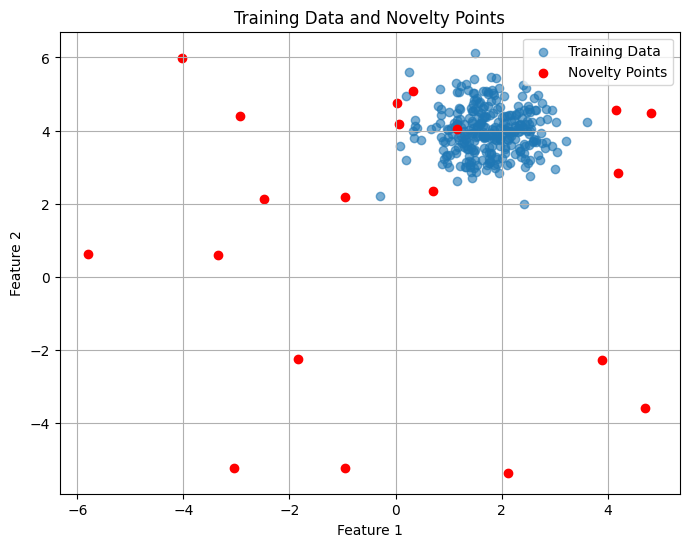

In [9]:
# Muat pustaka
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import OneClassSVM
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split

# Bangkitkan data latih (hanya normal)
X_train, _ = make_blobs(n_samples=300, centers=1, cluster_std=0.6, random_state=2024)

# Bangkitkan data uji (normal + novelty)
X_test_normal, _ = make_blobs(n_samples=100, centers=1, cluster_std=0.6, center_box=(0, 1), random_state=42)
X_test_novelty = np.random.uniform(low=-6, high=6, size=(20, 2))
X_test = np.vstack([X_test_normal, X_test_novelty])

# Visualisasikan data
plt.figure(figsize=(8, 6))
plt.scatter(X_train[:, 0], X_train[:, 1], label='Training Data', alpha=0.6)
plt.scatter(X_test_novelty[:, 0], X_test_novelty[:, 1], color='red', label='Novelty Points')
plt.title("Training Data and Novelty Points")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

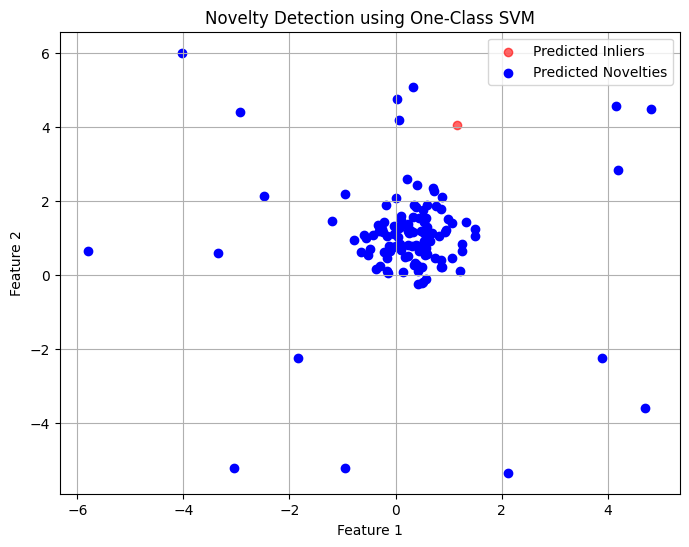

In [10]:
# Instansiasi dan fit model
model = OneClassSVM(kernel='rbf', gamma='scale', nu=0.05)
model.fit(X_train)

# Buat prediksi pada data uji
y_pred = model.predict(X_test)

# Gambar hasil prediksi
plt.figure(figsize=(8, 6))
plt.scatter(X_test[y_pred == 1, 0], X_test[y_pred == 1, 1], color='red', label='Predicted Inliers', alpha=0.6)
plt.scatter(X_test[y_pred == -1, 0], X_test[y_pred == -1, 1], color='blue', label='Predicted Novelties')
plt.title("Novelty Detection using One-Class SVM")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

> **Catatan:** Warna pada plot buku terbalik dari konvensi bab ini: di sini *Predicted Inliers* berwarna **merah** dan *Predicted Novelties* **biru**, sedangkan plot lain memakai merah untuk outlier. Kode dipertahankan persis seperti yang diterbitkan.

In [11]:
# Di mana data uji "normal" berada, dan bagaimana model menilainya (tambahan)
print("pusat data latih      :", X_train.mean(axis=0).round(2))
print("pusat data uji normal :", X_test_normal.mean(axis=0).round(2),
      f"-> berjarak {np.linalg.norm(X_train.mean(axis=0) - X_test_normal.mean(axis=0)):.2f} (≈ {np.linalg.norm(X_train.mean(axis=0) - X_test_normal.mean(axis=0)) / 0.6:.0f} deviasi standar)")
pred_normal, pred_novel = y_pred[:100], y_pred[100:]
print(f"uji normal diterima sebagai inlier : {(pred_normal == 1).sum()}/100")
print(f"novelty ditolak sebagai novelty    : {(pred_novel == -1).sum()}/20")
print(f"proporsi data latih di luar batas  : {(model.predict(X_train) == -1).mean():.3f} (nu = 0.05); support vector = {len(model.support_)}")

# Pembanding: data uji normal yang benar-benar berasal dari distribusi latih
X_same, _ = make_blobs(n_samples=400, centers=1, cluster_std=0.6, random_state=2024)
print(f"uji normal dari distribusi latih diterima: {(model.predict(X_same[300:]) == 1).sum()}/100")

pusat data latih      : [1.76 3.98]
pusat data uji normal : [0.3  0.98] -> berjarak 3.34 (≈ 6 deviasi standar)
uji normal diterima sebagai inlier : 0/100
novelty ditolak sebagai novelty    : 19/20
proporsi data latih di luar batas  : 0.047 (nu = 0.05); support vector = 17
uji normal dari distribusi latih diterima: 91/100


**Interpretasi output.** Hasil plot terlihat aneh: hampir **semua** titik uji berwarna biru (*novelty*), dan satu-satunya titik merah ("inlier") justru salah satu titik *novelty*. Sel tambahan menjelaskan penyebabnya:

* Data latih berpusat di (1,76; 3,98). Data uji "normal" dibangkitkan dengan `center_box=(0, 1)` dan `random_state=42`, sehingga pusatnya di (0,30; 0,98), sekitar **3,34 satuan atau ±6 deviasi standar** dari data latih. Dari sudut pandang model, 100 titik itu memang bukan data normal.
* Akibatnya **0 dari 100** titik uji normal diterima, sedangkan 19 dari 20 *novelty* ditolak. Satu *novelty* yang lolos kebetulan jatuh di dekat pusat data latih.
* Model sendiri bekerja sesuai teori: proporsi data latih di luar batas **0,047**, dekat `nu=0.05`, dengan 17 *support vector*. Jika data uji normal diambil dari distribusi yang **sama** dengan data latih, **91 dari 100** diterima.

Pelajaran penting: *novelty detection* menganggap apa pun di luar daerah data latih sebagai hal baru. Jika distribusi data normal bergeser (*data drift*), model akan menolak data normal yang baru. Kode buku tidak salah secara sintaksis, tetapi skenario ujinya tidak menguji apa yang dimaksudkan.

### Poin Penting
* *One-Class SVM* mempelajari batas data normal; `nu` ≈ proporsi data latih di luar batas (0,047 untuk `nu=0.05`).
* Data uji "normal" buku berasal dari lokasi lain (±6σ dari data latih), sehingga 0/100 diterima; dengan data dari distribusi yang sama, 91/100 diterima.
* *Novelty detection* sangat peka terhadap pergeseran distribusi.

## Resep 11.4 — *Local Outlier Factor* (LOF)

**Tujuan.** Mendeteksi outlier pada data dengan dua *cluster* berkepadatan berbeda (σ = 0,5 dan 1,5) ditambah 20 titik *noise*, memakai LOF yang membandingkan kepadatan setiap titik dengan kepadatan tetangganya.

### Teori

**Intuisi.** Jarak absolut ke tetangga saja menyesatkan jika kepadatan antar-daerah berbeda: titik di pinggir *cluster* yang renggang wajar berjarak jauh dari tetangganya, sedangkan jarak yang sama di dekat *cluster* yang rapat sudah mencurigakan. LOF membandingkan kepadatan **lokal** sebuah titik dengan kepadatan lokal tetangganya. Titik normal berkepadatan mirip tetangganya (LOF ≈ 1); titik yang jauh lebih jarang daripada lingkungannya mendapat LOF ≫ 1.

**Matematika.** Dengan $N_k(p)$ = $k$ tetangga terdekat $p$ dan $k\text{-dist}(o)$ = jarak $o$ ke tetangga ke-$k$-nya:
$$\text{reach-dist}_k(p,o)=\max\{k\text{-dist}(o),\,d(p,o)\},\qquad \text{lrd}_k(p)=\Bigg(\frac{\sum_{o\in N_k(p)}\text{reach-dist}_k(p,o)}{|N_k(p)|}\Bigg)^{-1},$$
$$\text{LOF}_k(p)=\frac{1}{|N_k(p)|}\sum_{o\in N_k(p)}\frac{\text{lrd}_k(o)}{\text{lrd}_k(p)}.$$
*Reachability distance* menghaluskan jarak sangat kecil di dalam *cluster* padat; *local reachability density* (lrd) adalah kebalikan jarak keterjangkauan rata-rata.

**Cara scikit-learn mengimplementasikannya.** `LocalOutlierFactor(n_neighbors=20, contamination='auto', novelty=False)`.

* `fit_predict` mengembalikan +1/−1 untuk data latih; `negative_outlier_factor_` $=-\text{LOF}$.
* Dengan `novelty=False` (default), **tidak ada** `predict` untuk data baru. Untuk *novelty detection*, pakai `novelty=True` lalu `predict` pada data baru (dan jangan pada data latih).

**Asumsi, kelebihan, keterbatasan.**

* Menangani *cluster* dengan kepadatan berbeda; skor relatif terhadap lingkungan.
* Pemilihan `n_neighbors` penting (terlalu kecil: berisik; terlalu besar: kehilangan sifat lokal). Biaya $O(n^2)$ tanpa indeks, sensitif terhadap skala.

### Kode

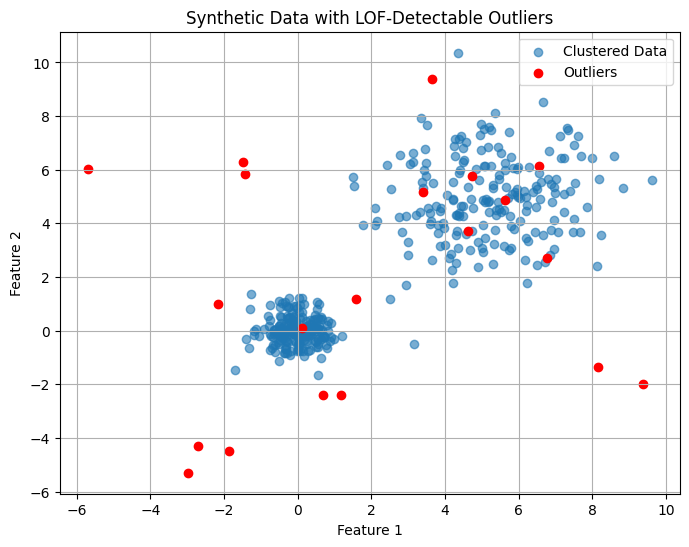

In [12]:
# Muat pustaka
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.neighbors import LocalOutlierFactor

# Buat data sintetis dengan cluster dan noise
X, _ = make_blobs(n_samples=400, centers=[[0, 0], [5, 5]], cluster_std=[0.5, 1.5], random_state=2024)
np.random.seed(2024)
outliers = np.random.uniform(low=-6, high=10, size=(20, 2))
X_with_outliers = np.vstack([X, outliers])

# Visualisasikan data
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], label="Clustered Data", alpha=0.6)
plt.scatter(outliers[:, 0], outliers[:, 1], color='red', label="Outliers")
plt.title("Synthetic Data with LOF-Detectable Outliers")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

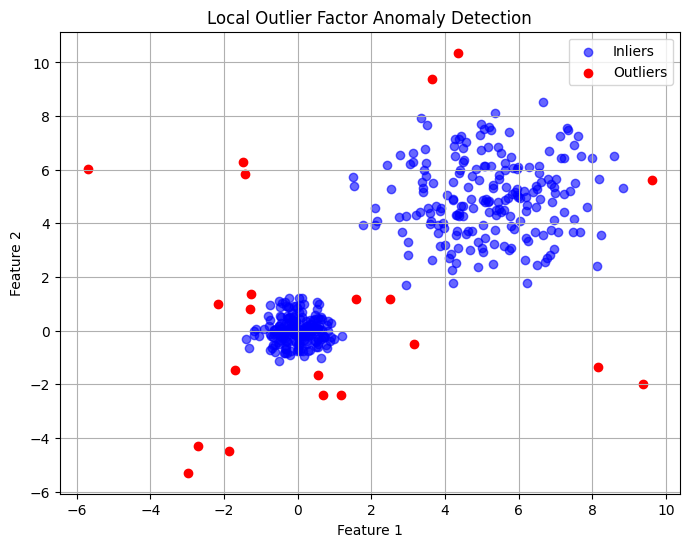

In [13]:
# Inisialisasi dan fit model
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
y_pred = lof.fit_predict(X_with_outliers)

# Gambar hasil prediksi
plt.figure(figsize=(8, 6))
plt.scatter(X_with_outliers[y_pred == 1, 0], X_with_outliers[y_pred == 1, 1],
            color='blue', label='Inliers', alpha=0.6)
plt.scatter(X_with_outliers[y_pred == -1, 0], X_with_outliers[y_pred == -1, 1],
            color='red', label='Outliers')
plt.title("Local Outlier Factor Anomaly Detection")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

In [14]:
# Hasil per kelompok, skor LOF, dan pembanding Isolation Forest pada data yang sama (tambahan)
y_true_lof = np.r_[np.zeros(400, int), np.ones(20, int)]
_, y_blob = make_blobs(n_samples=400, centers=[[0, 0], [5, 5]], cluster_std=[0.5, 1.5], random_state=2024)
flag = y_pred == -1
print(f"ditandai {flag.sum()} titik: {flag[400:].sum()} dari 20 noise, {flag[:400][y_blob == 0].sum()} dari cluster rapat, {flag[:400][y_blob == 1].sum()} dari cluster renggang")
lof_score = -lof.negative_outlier_factor_
print(f"LOF median: cluster rapat {np.median(lof_score[:400][y_blob == 0]):.2f}, cluster renggang {np.median(lof_score[:400][y_blob == 1]):.2f}, noise {np.median(lof_score[400:]):.2f}")
iso = IsolationForest(contamination=0.05, random_state=2024).fit(X_with_outliers)
print(f"ROC-AUC: LOF = {roc_auc_score(y_true_lof, lof_score):.4f}, Isolation Forest = {roc_auc_score(y_true_lof, -iso.decision_function(X_with_outliers)):.4f}")

ditandai 21 titik: 13 dari 20 noise, 4 dari cluster rapat, 4 dari cluster renggang
LOF median: cluster rapat 1.05, cluster renggang 1.04, noise 3.03
ROC-AUC: LOF = 0.7674, Isolation Forest = 0.8364


**Interpretasi output.** LOF menandai 21 titik (5 % dari 420): **13 dari 20** *noise*, 4 titik dari *cluster* rapat, dan 4 dari *cluster* renggang. Skor LOF median memperlihatkan inti idenya: titik di *cluster* rapat (1,05) dan *cluster* renggang (1,04) sama-sama bernilai ≈1, walaupun jarak antar-titik di *cluster* renggang tiga kali lebih besar. LOF menilai kepadatan **relatif terhadap tetangga**, bukan jarak absolut. *Noise* bermedian 3,03.

Hasilnya tidak sempurna: plot memperlihatkan beberapa titik *noise* yang jatuh **di dalam** *cluster* renggang tetap dianggap inlier, karena di sana mereka memang tidak lebih jarang daripada tetangganya. Pada data ini ROC-AUC LOF (0,767) bahkan di bawah *Isolation Forest* (0,836). Keunggulan LOF untuk kepadatan berbeda tidak otomatis berarti LOF selalu lebih baik.

### Poin Penting
* LOF membandingkan kepadatan lokal titik dengan tetangganya; titik di *cluster* rapat dan renggang sama-sama ber-LOF ≈ 1.
* 13 dari 20 *noise* tertangkap; *noise* yang jatuh di dalam *cluster* renggang tidak bisa dibedakan.
* LOF dengan `novelty=False` tidak punya `predict` untuk data baru.

## Resep 11.5 — Mengevaluasi Model Deteksi *Outlier*

**Tujuan.** Mengevaluasi *Isolation Forest* pada data berlabel (300 inlier + 30 outlier) dengan *confusion matrix*, *precision*/*recall*/F1, dan ROC-AUC.

### Teori

**Intuisi.** Jika label outlier tersedia (data simulasi, atau sebagian data yang sudah diperiksa ahli), deteksi outlier bisa dinilai seperti klasifikasi biner yang **sangat tidak seimbang**. Akurasi menyesatkan: model yang menyebut semua titik normal sudah 91 % "benar" di sini. Yang penting adalah berapa outlier tertangkap (*recall*) dan berapa tanda yang benar (*precision*).

**Matematika.** Dengan kelas positif = outlier: $P=\dfrac{TP}{TP+FP}$, $R=\dfrac{TP}{TP+FN}$, $F1=\dfrac{2PR}{P+R}$. ROC-AUC tidak bergantung ambang: ia sama dengan peluang skor anomali sebuah outlier acak lebih besar daripada skor sebuah inlier acak,
$$\text{AUC}=P\big(s(\mathbf{x}_{\text{out}})>s(\mathbf{x}_{\text{in}})\big).$$
Karena `decision_function` **negatif** untuk outlier, skor yang benar untuk AUC dengan label 1 = outlier adalah **$-$`decision_function`**.

**Cara scikit-learn mengimplementasikannya.** Konversi `np.where(y_pred == 1, 0, 1)` mengubah keluaran +1/−1 menjadi 0 (inlier) / 1 (outlier), lalu `confusion_matrix`, `classification_report`, dan `roc_auc_score(y_true, skor)` dipakai seperti biasa.

**Asumsi, kelebihan, keterbatasan.**

* Metrik berbasis label hanya mungkin bila label ada; tanpa label, buku menyarankan validasi ahli, galat rekonstruksi (*autoencoder*), atau stabilitas prediksi.
* Dengan `contamination` tetap, jumlah titik yang ditandai sudah ditentukan, sehingga *precision* dan *recall* saling terkait langsung.

### Kode

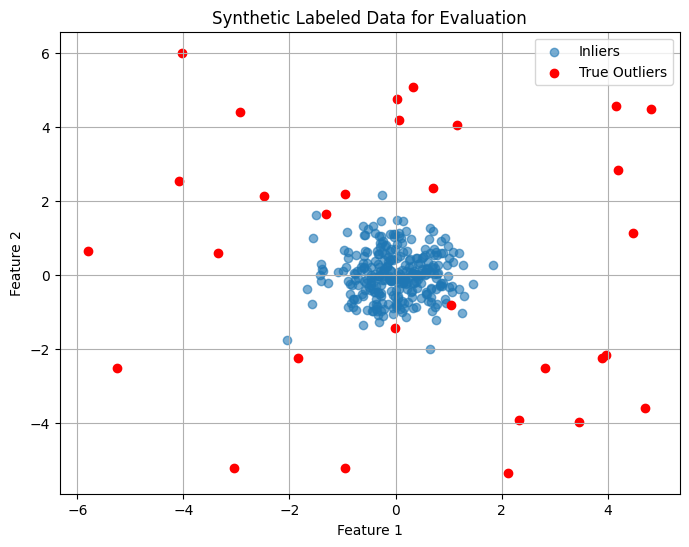

In [15]:
# Muat pustaka
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import seaborn as sns

# Bangkitkan data sintetis berlabel
X_inliers, _ = make_blobs(n_samples=300, centers=[[0, 0]], cluster_std=0.6, random_state=2024)
X_outliers = np.random.uniform(low=-6, high=6, size=(30, 2))
X = np.vstack([X_inliers, X_outliers])
y_true = np.array([0] * len(X_inliers) + [1] * len(X_outliers))  # 0 = inlier, 1 = outlier

# Visualisasikan data
plt.figure(figsize=(8, 6))
plt.scatter(X[y_true == 0][:, 0], X[y_true == 0][:, 1], label='Inliers', alpha=0.6)
plt.scatter(X[y_true == 1][:, 0], X[y_true == 1][:, 1], color='red', label='True Outliers')
plt.title("Synthetic Labeled Data for Evaluation")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

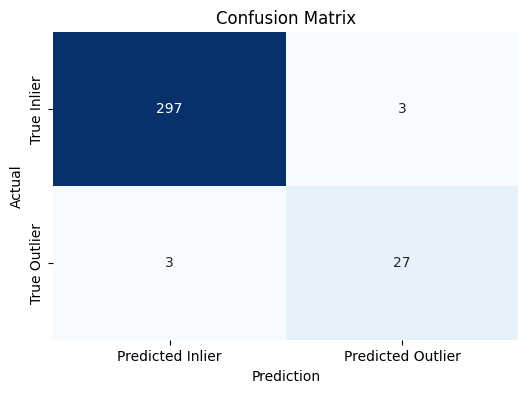

,precision,recall,f1-score,support
0,0.990,0.990,0.990,300
1,0.900,0.900,0.900,30
accuracy,0.982,0.982,0.982,1
macro avg,0.945,0.945,0.945,330
weighted avg,0.982,0.982,0.982,330


ROC-AUC Score: 0.005111111111111106


In [16]:
import pandas as pd

# Fit model dan ambil prediksi
model = IsolationForest(contamination=0.09, random_state=2024)
model.fit(X)
y_pred = model.predict(X)
y_pred_binary = np.where(y_pred == 1, 0, 1)  # ubah menjadi 0 = inlier, 1 = outlier

# Buat dan gambar confusion matrix
cm = confusion_matrix(y_true, y_pred_binary)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Inlier', 'Predicted Outlier'],
            yticklabels=['True Inlier', 'True Outlier'])
plt.xlabel('Prediction')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

# Cetak classification report sebagai DataFrame bergaya beserta AUC
report = classification_report(y_true, y_pred_binary, output_dict=True)
report = pd.DataFrame(report).transpose()
styled_report = (report
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_report)
print("ROC-AUC Score:", roc_auc_score(y_true, model.decision_function(X)))

> **Catatan:** Baris terakhir sel buku memberikan `model.decision_function(X)` langsung ke `roc_auc_score`. Karena skor itu **tinggi untuk inlier** sedangkan label positif (1) adalah **outlier**, AUC yang tercetak adalah AUC yang **terbalik**: nilainya sama dengan $1-\text{AUC}$ yang sebenarnya. Sel berikutnya menghitung AUC dengan tanda yang benar. Kode buku dipertahankan persis seperti yang diterbitkan.

In [17]:
# Angka confusion matrix, AUC dengan tanda yang benar, dan outlier yang lolos (tambahan)
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")
auc_book = roc_auc_score(y_true, model.decision_function(X))
auc_ok = roc_auc_score(y_true, -model.decision_function(X))
print(f"AUC sel buku = {auc_book:.4f}; AUC dengan skor -decision_function = {auc_ok:.4f} (jumlah keduanya = {auc_book + auc_ok:.4f})")
missed = X[(y_true == 1) & (y_pred_binary == 0)]
print("outlier yang lolos (koordinat):", missed.round(2).tolist(), "| jarak ke pusat (0,0):", np.linalg.norm(missed, axis=1).round(2).tolist())
print(f"akurasi 'semua normal' = {np.mean(y_true == 0):.3f}")

TN=297, FP=3, FN=3, TP=27
AUC sel buku = 0.0051; AUC dengan skor -decision_function = 0.9949 (jumlah keduanya = 1.0000)
outlier yang lolos (koordinat): [[-0.0, -1.44], [1.04, -0.83], [-1.32, 1.63]] | jarak ke pusat (0,0): [1.44, 1.32, 2.09]
akurasi 'semua normal' = 0.909


**Interpretasi output.**

* *Confusion matrix*: **297** inlier benar, **3** inlier salah tandai, **27** outlier tertangkap, **3** outlier lolos. Untuk kelas outlier, *precision* = *recall* = 27/30 = 0,90. Tiga outlier yang lolos berada 1,3–2,1 satuan dari pusat, yaitu di dalam atau di pinggir kelompok normal (deviasi standar 0,6), sehingga memang sulit dibedakan.
* **ROC-AUC yang dicetak buku (0,0051) salah tanda.** Nilai sekecil itu berarti model hampir selalu memberi skor outlier *lebih normal* daripada inlier, yang jelas bertentangan dengan *confusion matrix*. Penyebabnya, `decision_function` tinggi untuk inlier, sementara label positif adalah outlier. Dengan skor `-decision_function`, AUC = **0,9949**, dan kedua angka berjumlah tepat 1.
* Akurasi tidak informatif di sini: model yang menyebut semua titik normal sudah mendapat 0,909.

### Poin Penting
* Deteksi outlier berlabel dievaluasi seperti klasifikasi tidak seimbang: *precision*/*recall* outlier 0,90 (27/30).
* Untuk ROC-AUC, skor harus searah dengan label positif; sel buku memberi 0,0051, padahal AUC sebenarnya 0,9949.
* Akurasi menyesatkan (0,909 hanya dengan menebak "semua normal").

## Resep 11.6 — Menangani *Outlier* yang Terdeteksi

**Tujuan.** Setelah *Isolation Forest* menandai outlier, menerapkan tiga strategi: menghapus, mengganti dengan median, dan membatasi (*winsorization* persentil 5–95), lalu memvisualisasikan data sebelum dan sesudah penghapusan.

### Teori

**Intuisi.** Menemukan outlier hanyalah separuh pekerjaan; keputusan berikutnya adalah apa yang dilakukan terhadapnya, dan jawabannya bergantung pada **penyebab** outlier. Kesalahan sensor sebaiknya dibuang; transaksi penipuan justru adalah sinyal yang dicari.

**Matematika.**

* **Penghapusan:** $X'=\{\mathbf{x}_i : \text{bukan outlier}\}$.
* **Penggantian:** $\mathbf{x}_i\leftarrow\operatorname{median}(X_{\text{inlier}})$ untuk setiap outlier (per fitur).
* ***Winsorization* (capping):** setiap fitur dibatasi ke $[q_{0{,}05},\,q_{0{,}95}]$: $x_{ij}\leftarrow\min(\max(x_{ij},q_{0{,}05,j}),\,q_{0{,}95,j})$. Kuantil dihitung dari **seluruh** data, tidak bergantung pada detektor.
* ***Flagging:*** simpan titik apa adanya, tambahkan fitur biner `is_outlier`.

**Cara scikit-learn mengimplementasikannya.** Langkah penanganan memakai NumPy/pandas (`X[~outlier_mask]`, `np.median`, `Series.clip`); scikit-learn hanya menyediakan detektor.

**Asumsi, kelebihan, keterbatasan.**

* Penghapusan aman untuk data rusak tetapi bisa membuang sinyal penting dan mengurangi data.
* Penggantian median menjaga ukuran data tetapi menciptakan tumpukan titik identik di median (variansi tertekan, bias).
* *Winsorization* mempertahankan urutan tetapi bekerja **per fitur**: titik yang aneh hanya karena kombinasi fiturnya tidak tersentuh, dan titik normal di ekor distribusi ikut terpotong.
* Penanganan apa pun harus dipelajari dari data latih saja agar tidak terjadi kebocoran ke data uji.

### Kode

In [18]:
# Muat pustaka
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.datasets import make_blobs

# Bangkitkan dataset
X_inliers, _ = make_blobs(n_samples=300, centers=[[0, 0]], cluster_std=0.6, random_state=2024)
X_outliers = np.random.uniform(low=-6, high=6, size=(30, 2))
X = np.vstack([X_inliers, X_outliers])

#  Deteksi outlier dengan Isolation Forest
model = IsolationForest(contamination=0.09, random_state=2024)
model.fit(X)
outlier_mask = model.predict(X) == -1

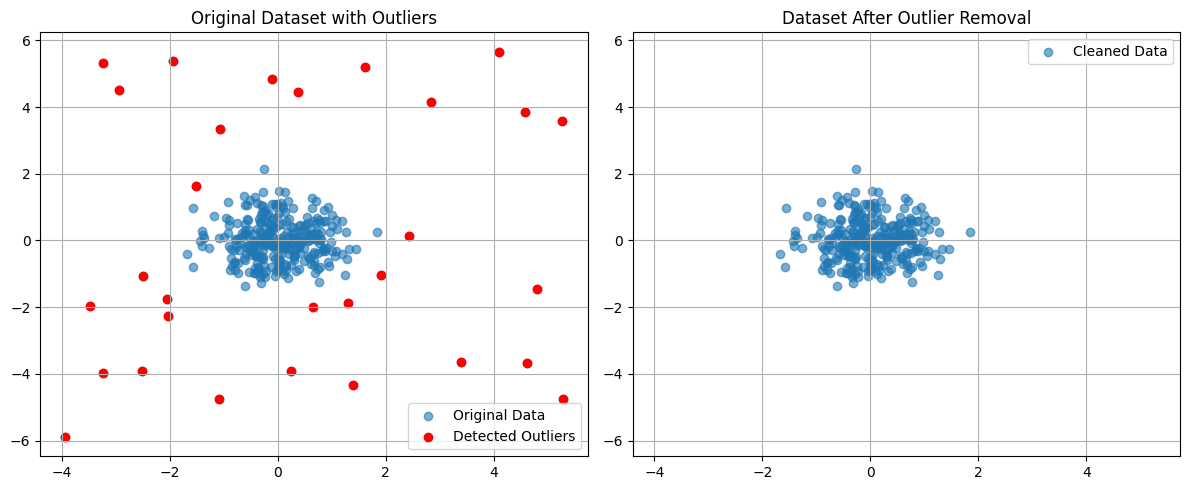

In [19]:
# Hapus outlier dari dataset
X_cleaned = X[~outlier_mask]

# Ganti outlier dengan median per fitur
X_replaced = X.copy()
median_vals = np.median(X[~outlier_mask], axis=0)
X_replaced[outlier_mask] = median_vals

# Batasi outlier ke rentang tertentu (winsorization)
X_df = pd.DataFrame(X, columns=['feature1', 'feature2'])
X_capped = X_df.copy()
for col in X_df.columns:
    lower = X_df[col].quantile(0.05)
    upper = X_df[col].quantile(0.95)
    X_capped[col] = X_df[col].clip(lower=lower, upper=upper)

# Visualisasikan dataset asli dan yang sudah dibersihkan dengan sumbu yang sama
plt.figure(figsize=(12, 5))

ax1 = plt.subplot(1, 2, 1)
ax1.scatter(X[:, 0], X[:, 1], label='Original Data', alpha=0.6)
ax1.scatter(X[outlier_mask][:, 0], X[outlier_mask][:, 1], color='red', label='Detected Outliers')
ax1.set_title('Original Dataset with Outliers')
ax1.legend()
ax1.grid(True)

ax2 = plt.subplot(1, 2, 2)
ax2.scatter(X_cleaned[:, 0], X_cleaned[:, 1], label='Cleaned Data', alpha=0.6)
ax2.set_title('Dataset After Outlier Removal')
ax2.legend()
ax2.grid(True)

ax2.set_xlim(ax1.get_xlim())
ax2.set_ylim(ax1.get_ylim())

plt.tight_layout()
plt.show()

In [20]:
# Ringkasan statistik ketiga strategi (tambahan)
def summarize(arr, name):
    a = np.asarray(arr)
    return {"strategi": name, "n": len(a), "std f1": a[:, 0].std(), "std f2": a[:, 1].std(),
            "min f1": a[:, 0].min(), "max f1": a[:, 0].max(), "titik unik": len(np.unique(a, axis=0))}
display(pd.DataFrame([summarize(X, "asli"), summarize(X_inliers, "inlier sebenarnya"), summarize(X_cleaned, "dihapus"),
                      summarize(X_replaced, "diganti median"), summarize(X_capped, "winsorization 5-95%")]).set_index("strategi").round(3))
print("batas winsorization:", {c: (round(float(X_df[c].quantile(0.05)), 3), round(float(X_df[c].quantile(0.95)), 3)) for c in X_df.columns})
inlier_cut = int(((X_capped.to_numpy()[:300] != X_inliers)).any(axis=1).sum())
print(f"titik normal yang ikut terpotong oleh winsorization: {inlier_cut} dari 300")

,n,std f1,std f2,min f1,max f1,titik unik
strategi,,,,,,
asli,330,1.059,1.288,-3.940,5.277,330
inlier sebenarnya,300,0.617,0.637,-2.052,1.842,300
dihapus,300,0.607,0.614,-1.675,1.842,300
diganti median,330,0.579,0.585,-1.675,1.842,301
winsorization 5-95%,330,0.678,0.686,-1.395,1.280,313


batas winsorization: {'feature1': (-1.395, 1.28), 'feature2': (-1.261, 1.314)}
titik normal yang ikut terpotong oleh winsorization: 19 dari 300


**Interpretasi output.** Plot kiri menandai 30 titik (merah) sebagai outlier dengan `contamination=0.09`, dan plot kanan menampilkan data tersisa pada sumbu yang sama, sehingga terlihat jelas yang tersisa hanya kelompok inti. Tabel tambahan membandingkan ketiga strategi dengan data inlier yang sebenarnya:

* **Dihapus:** 300 titik dengan deviasi standar 0,61/0,61, sangat dekat dengan inlier sebenarnya (0,62/0,64). Rentangnya sedikit menyempit (min −1,68 vs −2,05), artinya satu-dua titik normal di pinggir ikut dibuang.
* **Diganti median:** ukuran data tetap 330, tetapi 30 titik kini identik (hanya 301 titik unik) dan deviasi standar turun ke 0,58. Variansi **tertekan** di bawah nilai sebenarnya karena ada tumpukan titik di median.
* ***Winsorization* 5–95 %:** semua fitur dipotong ke sekitar [−1,4; 1,3]. Deviasi standar 0,68/0,69, masih di atas nilai sebenarnya karena outlier hanya dipindahkan ke tepi, bukan dibuang. Selain itu **19 dari 300 titik normal** ikut terpotong. *Winsorization* tidak memakai hasil detektor sama sekali; ia selalu memotong 10 % ekor setiap fitur.

### Poin Penting
* Penghapusan memulihkan statistik paling dekat dengan inlier sebenarnya (sd 0,61 vs 0,62).
* Penggantian median menjaga ukuran data tetapi menekan variansi (30 titik identik).
* *Winsorization* bekerja per fitur tanpa detektor, memotong 19 titik normal, dan membiarkan outlier di tepi rentang.

## Resep 11.7 — Memilih Teknik Deteksi yang Tepat

**Tujuan.** Merangkum karakteristik *Isolation Forest*, LOF, dan *One-Class SVM* dalam tabel, lalu (tambahan) menguji ketiganya pada data berlabel yang sama.

### Teori

**Intuisi.** Pilihan detektor bergantung pada ukuran dan dimensi data, ada-tidaknya data normal yang bersih, dan apakah kepadatan data bervariasi. Panduan buku:

* **Data besar dan berdimensi tinggi** → *Isolation Forest* (cepat, tidak bergantung jarak).
* ***Cluster* dengan kepadatan berbeda** → LOF (skor relatif terhadap lingkungan lokal).
* **Hanya tersedia data normal, ingin menilai data baru** → *One-Class SVM* (atau LOF dengan `novelty=True`).

**Matematika.** Ketiganya menghasilkan skor kontinu yang diubah menjadi keputusan dengan ambang: *Isolation Forest* memakai panjang jalur, LOF memakai rasio kepadatan, *One-Class SVM* memakai jarak bertanda ke batas kernel. Parameter `contamination` (IF, LOF) atau `nu` (OCSVM) menentukan ambang tersebut.

**Cara scikit-learn mengimplementasikannya.** Semua mengikuti API yang sama (+1/−1). Kode buku hanya **membuat** tiga objek ke variabel `model` yang sama (setiap baris menimpa baris sebelumnya) tanpa melatihnya, sebagai contoh konfigurasi. Sel tambahan melatih ketiganya pada data berlabel dari Resep 11.6 (300 inlier + 30 outlier) dan membandingkan ROC-AUC serta jumlah outlier yang tertangkap.

**Asumsi, kelebihan, keterbatasan.** Tabel buku adalah panduan umum, bukan aturan. Misalnya, kolom "*Learns From Unlabeled Data*: No (novelty only)" untuk *One-Class SVM* sebaiknya dibaca sebagai "dirancang untuk data latih yang bersih"; secara teknis OCSVM tetap bisa dilatih pada data tercampur dengan `nu` sebagai perkiraan proporsi outlier.

### Kode

In [21]:
# Muat pustaka
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM

# Buat tabel perbandingan metode
data = {
    "Algorithm": ["Isolation Forest", "Local Outlier Factor", "One-Class SVM"],
    "Handles High Dimensions": ["Yes", "No", "Sometimes"],
    "Learns From Unlabeled Data": ["Yes", "Yes", "No (novelty only)"],
    "Supports New Predictions": ["Yes", "No", "Yes"],
    "Scales to Large Data": ["Yes", "No", "No"],
    "Robust to Varying Densities": ["No", "Yes", "Partially"],
    "Main Strength": [
        "Fast, scalable, easy to use",
        "Detects local anomalies in varying densities",
        "Kernel-based boundary modeling"
    ]
}

summary_df = pd.DataFrame(data)
summary_df.set_index("Algorithm", inplace=True)
summary_df

,Handles High Dimensions,Learns From Unlabeled Data,Supports New Predictions,Scales to Large Data,Robust to Varying Densities,Main Strength
Algorithm,,,,,,
Isolation Forest,Yes,Yes,Yes,Yes,No,"Fast, scalable, easy to use"
Local Outlier Factor,No,Yes,No,No,Yes,Detects local anomalies in varying densities
One-Class SVM,Sometimes,No (novelty only),Yes,No,Partially,Kernel-based boundary modeling


In [22]:
# Jika data besar dan berdimensi tinggi, pertimbangkan:
# Isolation Forest lebih dianjurkan
model = IsolationForest(contamination=0.1, random_state=2024)

# Jika data memiliki cluster dengan kepadatan berbeda:
# Local Outlier Factor lebih cocok
model = LocalOutlierFactor(n_neighbors=20, contamination=0.1)

# Jika ingin melatih hanya pada data normal dan mendeteksi titik data baru nanti:
# One-Class SVM memungkinkan novelty detection
model = OneClassSVM(kernel='rbf', gamma='scale', nu=0.1)

In [23]:
# Uji ketiga konfigurasi pada data berlabel dari Resep 11.6 (tambahan)
X_eval = np.vstack([X_inliers, X_outliers]); y_eval = np.r_[np.zeros(300, int), np.ones(30, int)]
detectors = {
    "Isolation Forest": IsolationForest(contamination=0.1, random_state=2024),
    "LOF": LocalOutlierFactor(n_neighbors=20, contamination=0.1),
    "One-Class SVM": OneClassSVM(kernel='rbf', gamma='scale', nu=0.1),
}
rows = []
for name, det in detectors.items():
    if name == "LOF":
        pred = det.fit_predict(X_eval); score = -det.negative_outlier_factor_
    else:
        pred = det.fit(X_eval).predict(X_eval); score = -det.decision_function(X_eval)
    flag = (pred == -1).astype(int)
    rows.append({"detektor": name, "ditandai": flag.sum(), "outlier tertangkap (dari 30)": int(flag[y_eval == 1].sum()),
                 "normal salah tandai": int(flag[y_eval == 0].sum()), "ROC-AUC": roc_auc_score(y_eval, score)})
pd.DataFrame(rows).set_index("detektor").round(4)

,ditandai,outlier tertangkap (dari 30),normal salah tandai,ROC-AUC
detektor,,,,
Isolation Forest,33,27,6,0.9763
LOF,33,27,6,0.9791
One-Class SVM,33,26,7,0.9253


**Interpretasi output.** Tabel buku merangkum perbedaan utama: hanya LOF yang tidak bisa memprediksi data baru (dalam mode default), hanya *Isolation Forest* yang dinilai skalabel dan cocok untuk dimensi tinggi, dan hanya LOF yang benar-benar tahan terhadap kepadatan berbeda. Sel kode berikutnya hanya membuat objek; karena ketiga baris memakai nama `model`, yang tersisa setelah sel dijalankan hanyalah `OneClassSVM`.

Uji tambahan pada 330 titik berlabel dengan proporsi ditandai 10 % memberi hasil yang hampir sama untuk *Isolation Forest* dan LOF: keduanya menandai 33 titik, menangkap **27 dari 30** outlier, dan salah tandai 6 titik normal (ROC-AUC 0,976 dan 0,979). *One-Class SVM* sedikit lebih lemah: 26 tertangkap, 7 salah tandai, ROC-AUC 0,925, wajar karena ia dilatih pada data yang sudah tercampur outlier, bukan pada data normal yang bersih. Pada data sederhana seperti ini (satu kelompok bulat), pilihan algoritme tidak terlalu menentukan; perbedaannya baru penting pada data besar, berdimensi tinggi, atau berkepadatan tidak seragam.

### Poin Penting
* *Isolation Forest*: cepat dan skalabel; LOF: kepadatan lokal; *One-Class SVM*: batas kernel untuk *novelty*.
* Pada satu kelompok bulat + outlier acak, IF dan LOF setara (27/30, AUC ≈ 0,98), OCSVM sedikit di bawah (AUC 0,925).
* Pilih detektor berdasarkan sifat data dan apakah tersedia data normal yang bersih, bukan berdasarkan satu benchmark.

## Resep 11.8 — Latihan Praktis Deteksi *Novelty* dan *Outlier*

**Tujuan.** Menerapkan tiga detektor pada skenario simulasi: (1) *Isolation Forest* pada data terstandardisasi, (2) LOF pada dua *cluster* + *noise* dengan *confusion matrix*, (3) *One-Class SVM* yang dilatih pada data normal lalu menilai data campuran.

### Teori

* **Latihan 1:** data dibangkitkan dengan cara yang sama seperti Resep 11.5 (300 inlier + 30 outlier acak baru) tetapi **distandardisasi** dulu. *Isolation Forest* tidak bergantung pada skala (potongan acak per fitur), jadi standardisasi seharusnya hampir tidak mengubah hasil; latihan ini juga melatih membaca `classification_report` untuk kelas outlier.
* **Latihan 2:** data mirip Resep 11.4 (dua *cluster*, σ = 0,5 dan 1,5) dengan 20 *noise*, distandardisasi memakai `scaler` dari Latihan 1 (di-*fit* ulang dengan `fit_transform`). Perhatikan bahwa outlier uniform bisa jatuh di dalam *cluster* renggang.
* **Latihan 3:** skenario *novelty* yang benar: model dilatih pada 240 titik normal, lalu dievaluasi pada 60 titik normal yang tidak dilihat (dari distribusi yang **sama**) ditambah 30 *novelty*. Bandingkan dengan Resep 11.3, ketika data uji normal berasal dari lokasi berbeda.

Kode buku mengandalkan variabel dari sel sebelumnya (`scaler`, `make_blobs`, `sns`, `plt`), sehingga ketiga latihan harus dijalankan berurutan.

### Kode

### Kode — Latihan 1: Menerapkan *Isolation Forest*

In [24]:
# Muat pustaka
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from sklearn.datasets import make_blobs

# Bangkitkan data sintetis berisi inlier dan outlier
X_inliers, _ = make_blobs(n_samples=300, centers=[[0, 0]], cluster_std=0.6, random_state=2024)
X_outliers = np.random.uniform(low=-6, high=6, size=(30, 2))
X = np.vstack([X_inliers, X_outliers])
y_true = np.array([0] * len(X_inliers) + [1] * len(X_outliers))

# Skalakan data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Terapkan Isolation Forest
model = IsolationForest(contamination=0.09, random_state=2024)
model.fit(X_scaled)
y_pred = model.predict(X_scaled)
y_pred_binary = np.where(y_pred == 1, 0, 1)

# Evaluasi hasil
print("Exercise 1 Results:")

# Cetak classification report sebagai DataFrame bergaya
report = classification_report(y_true, y_pred_binary, output_dict=True)
report = pd.DataFrame(report).transpose()
styled_report = (report
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_report)

Exercise 1 Results:


,precision,recall,f1-score,support
0,0.987,0.987,0.987,300
1,0.867,0.867,0.867,30
accuracy,0.976,0.976,0.976,1
macro avg,0.927,0.927,0.927,330
weighted avg,0.976,0.976,0.976,330


In [25]:
# Angka utama Latihan 1 (tambahan)
tn, fp, fn, tp = confusion_matrix(y_true, y_pred_binary).ravel()
print(f"tertangkap {tp}/30, normal salah tandai {fp}, outlier lolos {fn}; "
      f"ROC-AUC = {roc_auc_score(y_true, -model.decision_function(X_scaled)):.4f}")

tertangkap 26/30, normal salah tandai 4, outlier lolos 4; ROC-AUC = 0.9904


**Interpretasi output.** Dengan data terstandardisasi, *Isolation Forest* menangkap **26 dari 30** outlier dengan **4** titik normal salah tandai, sehingga *precision* dan *recall* kelas outlier sama-sama 0,867, dan ROC-AUC 0,990. Angkanya sedikit berbeda dari Resep 11.5 (27/30) karena 30 outlier dibangkitkan ulang secara acak, bukan karena standardisasi: *Isolation Forest* memotong setiap fitur secara terpisah, sehingga transformasi linear per fitur hampir tidak memengaruhinya.

### Kode — Latihan 2: LOF pada Dataset Mirip Jaringan


Exercise 2 Results:


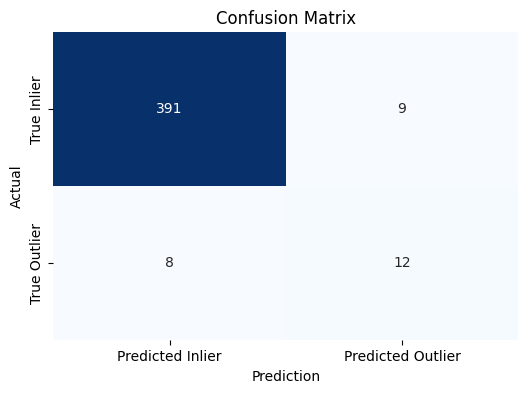

,precision,recall,f1-score,support
0,0.980,0.978,0.979,400
1,0.571,0.600,0.585,20
accuracy,0.960,0.960,0.960,1
macro avg,0.776,0.789,0.782,420
weighted avg,0.960,0.960,0.960,420


In [26]:
# Muat pustaka
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

# Bangkitkan data ber-cluster dengan noise sintetis
X_clustered, _ = make_blobs(n_samples=400, centers=[[0, 0], [5, 5]], cluster_std=[0.5, 1.5], random_state=2024)
X_noise = np.random.uniform(low=-6, high=10, size=(20, 2))
X_combined = np.vstack([X_clustered, X_noise])
y_combined = np.array([0] * 400 + [1] * 20)

# Skalakan data
X_scaled = scaler.fit_transform(X_combined)

# Terapkan Local Outlier Factor
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
y_pred = lof.fit_predict(X_scaled)
y_pred_binary = np.where(y_pred == 1, 0, 1)

# Evaluasi prediksi
print("\nExercise 2 Results:")
cm = confusion_matrix(y_combined, y_pred_binary)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Inlier', 'Predicted Outlier'],
            yticklabels=['True Inlier', 'True Outlier'])
plt.xlabel('Prediction')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

report = classification_report(y_combined, y_pred_binary, output_dict=True)
report = pd.DataFrame(report).transpose()
styled_report = (report
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_report)

In [27]:
# Angka utama Latihan 2 (tambahan)
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}; ROC-AUC = {roc_auc_score(y_combined, -lof.negative_outlier_factor_):.4f}")
noise_in_sparse = np.linalg.norm(X_noise - np.array([5, 5]), axis=1) < 3 * 1.5
print(f"noise yang jatuh dalam radius 3σ cluster renggang: {noise_in_sparse.sum()} dari 20")

TN=391, FP=9, FN=8, TP=12; ROC-AUC = 0.9000
noise yang jatuh dalam radius 3σ cluster renggang: 6 dari 20


**Interpretasi output.** *Confusion matrix* LOF: **391** inlier benar, **9** salah tandai, **12** dari 20 *noise* tertangkap, dan **8** lolos (*recall* outlier 0,60; *precision* 12/21 ≈ 0,57). ROC-AUC 0,900. Sel tambahan memperlihatkan salah satu alasan: **6 dari 20** titik *noise* jatuh dalam radius 3σ dari pusat *cluster* renggang, sehingga secara kepadatan mereka tampak seperti anggota *cluster*. Dibanding Latihan 1, skenario dua *cluster* dengan kepadatan berbeda jelas lebih sulit.

### Kode — Latihan 3: *One-Class SVM* untuk Data Sensor Manufaktur

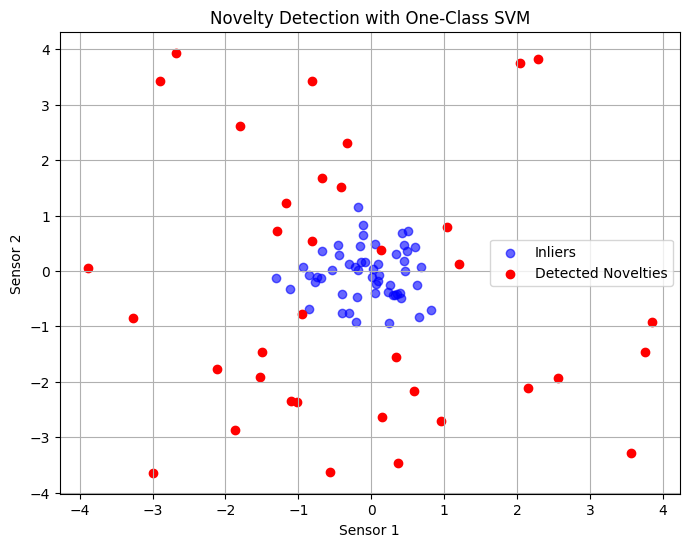

In [28]:
# Muat pustaka
from sklearn.svm import OneClassSVM
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Bangkitkan data normal dan novelty
X_normal = np.random.normal(loc=0.0, scale=0.5, size=(300, 2))
X_novelty = np.random.uniform(low=-4, high=4, size=(30, 2))
X_train, X_test = train_test_split(X_normal, test_size=0.2, random_state=2024)
X_eval = np.vstack([X_test, X_novelty])

# Fit One-Class SVM pada data normal
svm_model = OneClassSVM(kernel='rbf', gamma='scale', nu=0.05)
svm_model.fit(X_train)
y_pred = svm_model.predict(X_eval)

# Visualisasikan prediksi
plt.figure(figsize=(8, 6))
plt.scatter(X_eval[y_pred == 1][:, 0], X_eval[y_pred == 1][:, 1], color='blue', label='Inliers', alpha=0.6)
plt.scatter(X_eval[y_pred == -1][:, 0], X_eval[y_pred == -1][:, 1], color='red', label='Detected Novelties')
plt.title("Novelty Detection with One-Class SVM")
plt.xlabel("Sensor 1")
plt.ylabel("Sensor 2")
plt.legend()
plt.grid(True)
plt.show()

In [29]:
# Angka utama Latihan 3 (tambahan)
y_eval3 = np.r_[np.zeros(len(X_test), int), np.ones(len(X_novelty), int)]
flag = (y_pred == -1).astype(int)
print(f"uji normal diterima: {(flag[y_eval3 == 0] == 0).sum()}/{len(X_test)}, novelty ditolak: {flag[y_eval3 == 1].sum()}/{len(X_novelty)}")
print(f"ROC-AUC = {roc_auc_score(y_eval3, -svm_model.decision_function(X_eval)):.4f}")
inside = np.linalg.norm(X_novelty, axis=1) < 2 * 0.5 * np.sqrt(2)
print(f"novelty yang jatuh di dalam radius ≈2σ data normal: {inside.sum()} dari {len(X_novelty)}")

uji normal diterima: 53/60, novelty ditolak: 29/30
ROC-AUC = 0.9961
novelty yang jatuh di dalam radius ≈2σ data normal: 1 dari 30


**Interpretasi output.** Kali ini skenario *novelty* disusun dengan benar: model dilatih pada 240 titik normal, lalu dievaluasi pada 60 titik normal yang tidak dilihat dari distribusi **yang sama** ditambah 30 *novelty*. Hasilnya **53 dari 60** titik normal diterima dan **29 dari 30** *novelty* ditolak, dengan ROC-AUC **0,996**. Plot memperlihatkan batas yang mengikuti awan data normal; satu-satunya *novelty* yang lolos jatuh di dalam awan itu. Tujuh titik normal yang ditolak berada di tepi awan, konsekuensi `nu=0.05` (sekitar 5 % data normal memang diizinkan berada di luar batas, dan pada sampel kecil bisa lebih). Bandingkan dengan Resep 11.3: algoritme yang sama, tetapi data uji yang dibangkitkan dengan benar membuat hasilnya jauh lebih masuk akal.

### Poin Penting
* *Isolation Forest* hampir tidak terpengaruh standardisasi; 26/30 outlier tertangkap (AUC 0,990).
* LOF pada dua *cluster* + *noise*: 12/20 tertangkap, karena sebagian *noise* jatuh di dalam *cluster* renggang.
* *One-Class SVM* yang diuji dengan data normal dari distribusi yang sama: 53/60 normal diterima, 29/30 *novelty* ditolak (AUC 0,996).

## Ringkasan Bab

| Resep | Konsep | Kelas/fungsi sklearn utama | Poin penting |
|---|---|---|---|
| 11.1 Pengantar | *Outlier* vs *novelty*, `contamination` | `LocalOutlierFactor` | 16 titik ditandai, 15/20 outlier tertangkap; 5 outlier jatuh di dalam kelompok normal. |
| 11.2 *Isolation Forest* | Panjang jalur isolasi, skor $2^{-E[h]/c(\psi)}$ | `IsolationForest` | 14/20 tertangkap, ROC-AUC 0,988 (setara LOF). |
| 11.3 *One-Class SVM* | Batas data normal di ruang kernel, `nu` | `OneClassSVM` | Data uji normal buku bergeser ±6σ → 0/100 diterima; dari distribusi sama → 91/100. |
| 11.4 LOF | Kepadatan lokal relatif | `LocalOutlierFactor` | LOF ≈ 1 di *cluster* rapat maupun renggang; 13/20 *noise* tertangkap, AUC 0,767. |
| 11.5 Evaluasi | *Precision*/*recall*/F1, ROC-AUC | `confusion_matrix`, `roc_auc_score` | 27/30 tertangkap; AUC buku 0,0051 salah tanda, yang benar 0,9949. |
| 11.6 Penanganan | Hapus, ganti median, *winsorization* | NumPy/pandas | Penghapusan paling dekat dengan statistik sebenarnya; *winsorization* memotong 19 titik normal. |
| 11.7 Memilih Teknik | Perbandingan IF / LOF / OCSVM | ketiganya | Pada satu kelompok bulat: IF ≈ LOF (AUC ≈ 0,98) > OCSVM (0,925). |
| 11.8 Latihan Praktis | IF terstandardisasi, LOF dua *cluster*, OCSVM *novelty* | ketiganya | 26/30; 12/20; 53/60 normal diterima dan 29/30 *novelty* ditolak. |

**Langkah selanjutnya.** Bab ini menemukan dua kesalahan halus dalam kode buku: skenario uji *novelty* yang datanya bergeser, dan ROC-AUC dengan tanda skor terbalik. Keduanya mengingatkan bahwa angka evaluasi hanya sebaik cara evaluasinya disusun. Bab 12 membahas topik ini secara langsung: *cross-validation*, pemilihan model, dan diagnosis generalisasi.

## Referensi

* Sukup, J. (2025). *scikit-learn Cookbook, Third Edition*. Packt Publishing. Bab 11.
* Repositori kode resmi: <https://github.com/PacktPublishing/Scikit-Learn-Cookbook-Third-Edition>
* scikit-learn User Guide — Novelty and Outlier Detection: <https://scikit-learn.org/1.5/modules/outlier_detection.html>
* Liu, F. T., Ting, K. M., & Zhou, Z.-H. (2008). Isolation Forest. *Proceedings of the IEEE International Conference on Data Mining (ICDM)*, 413–422.
* Breunig, M. M., Kriegel, H.-P., Ng, R. T., & Sander, J. (2000). LOF: Identifying density-based local outliers. *Proceedings of ACM SIGMOD*, 93–104.
* Schölkopf, B., Platt, J. C., Shawe-Taylor, J., Smola, A. J., & Williamson, R. C. (2001). Estimating the support of a high-dimensional distribution. *Neural Computation*, 13(7), 1443–1471.
* Chandola, V., Banerjee, A., & Kumar, V. (2009). Anomaly detection: A survey. *ACM Computing Surveys*, 41(3), 15.